In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
print("All libraries imported successfully!")

#LOAD THE DATASET
df = pd.read_csv("C:\\Users\\Nikhil\\Desktop\\SALES\\superstore_sales.csv")
#CHECKING DATASET IS LOADED OR NOT
df.head()

All libraries imported successfully!


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2.0,0.00,41.9136
1,2,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3.0,0.00,219.5820
2,3,CA-2017-138688,6/12/2017,6/16/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2.0,0.00,6.8714
3,4,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5.0,0.45,-383.0310
4,5,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2.0,0.20,2.5164


In [49]:
df.columns = df.columns.str.strip().str.replace(" ","_")
df.columns = df.columns.str.upper()

In [46]:
df.shape     #its shown the number of rows and columns

(10800, 21)

In [50]:
df.columns   #identify all available columns

Index(['ROW_ID', 'ORDER_ID', 'ORDER_DATE', 'SHIP_DATE', 'SHIP_MODE',
       'CUSTOMER_ID', 'CUSTOMER_NAME', 'SEGMENT', 'COUNTRY', 'CITY', 'STATE',
       'POSTAL_CODE', 'REGION', 'PRODUCT_ID', 'CATEGORY', 'SUB-CATEGORY',
       'PRODUCT_NAME', 'SALES', 'QUANTITY', 'DISCOUNT', 'PROFIT'],
      dtype='object')

In [33]:
df.info()    #gives all general info about dataset

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10800 entries, 0 to 10799
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         10800 non-null  object 
 1   Order ID       10800 non-null  object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9983 non-null   float64
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          9994 non-null   float64
 18  Quanti

In [41]:
print(df.isnull().sum())   #how many missing values in each column

print("duplicate rows are:",df.duplicated().sum())  #shows how many duplicate rows

df.describe()    #this gives mean median max min like a stats

Row ID             0
Order ID           0
Order Date       806
Ship Date        806
Ship Mode        806
Customer ID      806
Customer Name    806
Segment          806
Country          806
City             806
State            806
Postal Code      817
Region           806
Product ID       806
Category         806
Sub-Category     806
Product Name     806
Sales            806
Quantity         806
Discount         806
Profit           806
dtype: int64
duplicate rows are: 504


,Postal Code,Sales,Quantity,Discount,Profit
count,9983.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,55245.233297,229.858001,3.789574,0.156203,28.656896
std,32038.715955,623.245101,2.225110,0.206452,234.260108
min,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,57103.000000,54.490000,3.000000,0.200000,8.666500
75%,90008.000000,209.940000,5.000000,0.200000,29.364000
max,99301.000000,22638.480000,14.000000,0.800000,8399.976000


In [53]:
missing_percentage=(df.isnull().mean()*100).round(2)  #missing values analysis in percetage for each column
print(missing_percentage)

ROW_ID           0.00
ORDER_ID         0.00
ORDER_DATE       7.46
SHIP_DATE        7.46
SHIP_MODE        7.46
CUSTOMER_ID      7.46
CUSTOMER_NAME    7.46
SEGMENT          7.46
COUNTRY          7.46
CITY             7.46
STATE            7.46
POSTAL_CODE      7.56
REGION           7.46
PRODUCT_ID       7.46
CATEGORY         7.46
SUB-CATEGORY     7.46
PRODUCT_NAME     7.46
SALES            7.46
QUANTITY         7.46
DISCOUNT         7.46
PROFIT           7.46
dtype: float64


In [54]:
missing_data=df[df.isnull().any(axis=1)]  #identifying rows with missing values
missing_data.head(10)

#df.isnull() – checks every cell for missing values.
#.any(axis=1) – checks whether at least one value is missing in a row.
#df[...] – selects only rows containing missing values.
#missing_data – stores those rows in a separate DataFrame.
#.head(10) – displays the first 10 incomplete rows.

,ROW_ID,ORDER_ID,ORDER_DATE,SHIP_DATE,SHIP_MODE,CUSTOMER_ID,CUSTOMER_NAME,SEGMENT,COUNTRY,CITY,...,POSTAL_CODE,REGION,PRODUCT_ID,CATEGORY,SUB-CATEGORY,PRODUCT_NAME,SALES,QUANTITY,DISCOUNT,PROFIT
2234,2235,CA-2018-104066,12/5/2018,12/10/2018,Standard Class,QJ-19255,Quincy Jones,Corporate,United States,Burlington,...,NaN,East,TEC-AC-10001013,Technology,Accessories,Logitech ClearChat Comfort/USB Headset H390,205.03,7.0,0.0,67.6599
5274,5275,CA-2016-162887,11/7/2016,11/9/2016,Second Class,SV-20785,Stewart Visinsky,Consumer,United States,Burlington,...,NaN,East,FUR-CH-10000595,Furniture,Chairs,Safco Contoured Stacking Chairs,715.20,3.0,0.0,178.8000
8798,8799,US-2017-150140,4/6/2017,4/10/2017,Standard Class,VM-21685,Valerie Mitchum,Home Office,United States,Burlington,...,NaN,East,TEC-PH-10002555,Technology,Phones,Nortel Meridian M5316 Digital phone,1294.75,5.0,0.0,336.6350
9146,9147,US-2017-165505,1/23/2017,1/27/2017,Standard Class,CB-12535,Claudia Bergmann,Corporate,United States,Burlington,...,NaN,East,TEC-AC-10002926,Technology,Accessories,Logitech Wireless Marathon Mouse M705,99.98,2.0,0.0,42.9914
9147,9148,US-2017-165505,1/23/2017,1/27/2017,Standard Class,CB-12535,Claudia Bergmann,Corporate,United States,Burlington,...,NaN,East,OFF-AR-10003477,Office Supplies,Art,4009 Highlighters,8.04,6.0,0.0,2.7336
9148,9149,US-2017-165505,1/23/2017,1/27/2017,Standard Class,CB-12535,Claudia Bergmann,Corporate,United States,Burlington,...,NaN,East,OFF-ST-10001526,Office Supplies,Storage,Iceberg Mobile Mega Data/Printer Cart,1564.29,13.0,0.0,406.7154
9386,9387,US-2018-127292,1/19/2018,1/23/2018,Standard Class,RM-19375,Raymond Messe,Consumer,United States,Burlington,...,NaN,East,OFF-PA-10000157,Office Supplies,Paper,Xerox 191,79.92,4.0,0.0,37.5624
9387,9388,US-2018-127292,1/19/2018,1/23/2018,Standard Class,RM-19375,Raymond Messe,Consumer,United States,Burlington,...,NaN,East,OFF-PA-10001970,Office Supplies,Paper,Xerox 1881,12.28,1.0,0.0,5.7716
9388,9389,US-2018-127292,1/19/2018,1/23/2018,Standard Class,RM-19375,Raymond Messe,Consumer,United States,Burlington,...,NaN,East,OFF-AP-10000828,Office Supplies,Appliances,Avanti 4.4 Cu. Ft. Refrigerator,542.94,3.0,0.0,152.0232
9389,9390,US-2018-127292,1/19/2018,1/23/2018,Standard Class,RM-19375,Raymond Messe,Consumer,United States,Burlington,...,NaN,East,OFF-EN-10001509,Office Supplies,Envelopes,Poly String Tie Envelopes,2.04,1.0,0.0,0.9588


In [55]:
missing_data.shape   # it will return two number rows(817) and columns(21) 817 records contain at least one missing value.

(817, 21)

In [56]:
df.isnull().sum(axis=1).value_counts().sort_index()

#isnull() identifies missing values.
#sum(axis=1) counts missing values in each row.
#value_counts() counts how many rows have each missing-value count.
#sort_index() arranges the results.


0     9983
1       11
19     806
Name: count, dtype: int64

In [57]:
df.loc[df.isnull().sum(axis=1) == 1].isnull().sum()

#df refers to the original DataFrame (your dataset).
#isnull() identifies missing values (NaN) in every cell.
#sum(axis=1) counts missing values in each row.
#== 1 selects only rows containing exactly one missing value.
#df.loc[] extracts the rows that satisfy the condition.
#isnull() checks for missing values again in the selected rows.
#sum() counts missing values in each column

ROW_ID            0
ORDER_ID          0
ORDER_DATE        0
SHIP_DATE         0
SHIP_MODE         0
CUSTOMER_ID       0
CUSTOMER_NAME     0
SEGMENT           0
COUNTRY           0
CITY              0
STATE             0
POSTAL_CODE      11
REGION            0
PRODUCT_ID        0
CATEGORY          0
SUB-CATEGORY      0
PRODUCT_NAME      0
SALES             0
QUANTITY          0
DISCOUNT          0
PROFIT            0
dtype: int64

In [58]:
df.loc[df['POSTAL_CODE'].isnull(),['ROW_ID', 'CITY', 'STATE', 'REGION', 'POSTAL_CODE']]

#df.loc[] selects specific rows and columns.
#POSTAL_CODE.isnull() identifies rows with missing postal codes.
#['ROW_ID', 'CITY', 'STATE', 'REGION', 'POSTAL_CODE'] displays only the five selected columns.

,ROW_ID,CITY,STATE,REGION,POSTAL_CODE
2234,2235,Burlington,Vermont,East,NaN
5274,5275,Burlington,Vermont,East,NaN
8798,8799,Burlington,Vermont,East,NaN
9146,9147,Burlington,Vermont,East,NaN
9147,9148,Burlington,Vermont,East,NaN
...,...,...,...,...,...
10795,Yes,NaN,NaN,NaN,NaN
10796,Yes,NaN,NaN,NaN,NaN
10797,Yes,NaN,NaN,NaN,NaN
10798,Yes,NaN,NaN,NaN,NaN


In [59]:
one_missing = df.loc[df.isnull().sum(axis=1) == 1]

one_missing[['ROW_ID', 'CITY', 'STATE', 'REGION', 'POSTAL_CODE']]

,ROW_ID,CITY,STATE,REGION,POSTAL_CODE
2234,2235,Burlington,Vermont,East,NaN
5274,5275,Burlington,Vermont,East,NaN
8798,8799,Burlington,Vermont,East,NaN
9146,9147,Burlington,Vermont,East,NaN
9147,9148,Burlington,Vermont,East,NaN
9148,9149,Burlington,Vermont,East,NaN
9386,9387,Burlington,Vermont,East,NaN
9387,9388,Burlington,Vermont,East,NaN
9388,9389,Burlington,Vermont,East,NaN
9389,9390,Burlington,Vermont,East,NaN


In [60]:
mostly_missing = df.loc[df.isnull().sum(axis=1) == 19]
mostly_missing.head(10)

,ROW_ID,ORDER_ID,ORDER_DATE,SHIP_DATE,SHIP_MODE,CUSTOMER_ID,CUSTOMER_NAME,SEGMENT,COUNTRY,CITY,...,POSTAL_CODE,REGION,PRODUCT_ID,CATEGORY,SUB-CATEGORY,PRODUCT_NAME,SALES,QUANTITY,DISCOUNT,PROFIT
9994,Person,Region,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9995,Anna Andreadi,West,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9996,Chuck Magee,East,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9997,Kelly Williams,Central,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9998,Cassandra Brandow,South,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9999,Returned,Order ID,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10000,Yes,CA-2015-100762,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10001,Yes,CA-2015-100762,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10002,Yes,CA-2015-100762,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10003,Yes,CA-2015-100762,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [65]:
mostly_missing[["ROW_ID","ORDER_ID"]].tail(10)
#mostly_missing selects the 806 records with 19 missing values.
#[['ROW_ID', 'ORDER_ID']] selects only these two columns.
#tail(10) displays the last 10 records.

,ROW_ID,ORDER_ID
10790,Yes,US-2018-147886
10791,Yes,US-2018-147886
10792,Yes,US-2018-147886
10793,Yes,US-2018-147886
10794,Yes,US-2018-147886
10795,Yes,US-2018-147886
10796,Yes,US-2018-147998
10797,Yes,US-2018-151127
10798,Yes,US-2018-155999
10799,Yes,US-2018-155999


In [62]:
mostly_missing['ROW_ID'].value_counts(dropna=False).head(20)
#mostly_missing['ROW_ID'] selects the ROW_ID column.
#value_counts() counts how often each value appears.
#dropna=False includes missing values in the count.
#head(20) displays the first 20 results.


ROW_ID
Yes                  800
Person                 1
Anna Andreadi          1
Chuck Magee            1
Kelly Williams         1
Cassandra Brandow      1
Returned               1
Name: count, dtype: int64

In [63]:
df.tail(15)
#df refers to our original dataset.
#tail(15) displays the last 15 rows.
#This helps us inspect the suspicious records in their original structure


,ROW_ID,ORDER_ID,ORDER_DATE,SHIP_DATE,SHIP_MODE,CUSTOMER_ID,CUSTOMER_NAME,SEGMENT,COUNTRY,CITY,...,POSTAL_CODE,REGION,PRODUCT_ID,CATEGORY,SUB-CATEGORY,PRODUCT_NAME,SALES,QUANTITY,DISCOUNT,PROFIT
10785,Yes,US-2018-118087,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10786,Yes,US-2018-123834,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10787,Yes,US-2018-136679,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10788,Yes,US-2018-136679,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10789,Yes,US-2018-147886,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10790,Yes,US-2018-147886,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10791,Yes,US-2018-147886,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10792,Yes,US-2018-147886,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10793,Yes,US-2018-147886,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10794,Yes,US-2018-147886,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [64]:
df[df['ROW_ID'] == 'Yes'].shape
#df['ROW_ID'] == 'Yes' finds rows where ROW_ID is Yes.
#df[...] filters those rows.
#.shape returns the number of rows and columns.


(800, 21)

In [66]:
df[df['ROW_ID'] != 'Yes'][['ROW_ID', 'ORDER_ID']].tail(20)
#!= 'Yes' selects rows where ROW_ID is not Yes.
#[['ROW_ID', 'ORDER_ID']] displays only two columns.
#.tail(20) displays the last 20 rows.E


,ROW_ID,ORDER_ID
9980,9981,US-2016-151435
9981,9982,CA-2018-163566
9982,9983,US-2017-157728
9983,9984,US-2017-157728
9984,9985,CA-2016-100251
9985,9986,CA-2016-100251
9986,9987,CA-2017-125794
9987,9988,CA-2018-163629
9988,9989,CA-2018-163629
9989,9990,CA-2015-110422


In [67]:
df.tail(20)

,ROW_ID,ORDER_ID,ORDER_DATE,SHIP_DATE,SHIP_MODE,CUSTOMER_ID,CUSTOMER_NAME,SEGMENT,COUNTRY,CITY,...,POSTAL_CODE,REGION,PRODUCT_ID,CATEGORY,SUB-CATEGORY,PRODUCT_NAME,SALES,QUANTITY,DISCOUNT,PROFIT
10780,Yes,US-2018-118087,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10781,Yes,US-2018-118087,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10782,Yes,US-2018-118087,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10783,Yes,US-2018-118087,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10784,Yes,US-2018-118087,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10785,Yes,US-2018-118087,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10786,Yes,US-2018-123834,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10787,Yes,US-2018-136679,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10788,Yes,US-2018-136679,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10789,Yes,US-2018-147886,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [68]:
df[df['ROW_ID'] != 'Yes'][['ROW_ID', 'ORDER_ID']].tail(20)

#df['ROW_ID'] != 'Yes' selects records that don't have Yes in ROW_ID.
#[['ROW_ID', 'ORDER_ID']] displays two columns.
#.tail(20) shows the last 20 matching records.

,ROW_ID,ORDER_ID
9980,9981,US-2016-151435
9981,9982,CA-2018-163566
9982,9983,US-2017-157728
9983,9984,US-2017-157728
9984,9985,CA-2016-100251
9985,9986,CA-2016-100251
9986,9987,CA-2017-125794
9987,9988,CA-2018-163629
9988,9989,CA-2018-163629
9989,9990,CA-2015-110422


In [69]:
df.iloc[9990:10005][['ROW_ID', 'ORDER_ID']]

#iloc selects rows using their positions.
#9990:10005 displays rows around the boundary.
#We display only ROW_ID and ORDER_ID.

,ROW_ID,ORDER_ID
9990,9991,CA-2018-121258
9991,9992,CA-2018-121258
9992,9993,CA-2018-121258
9993,9994,CA-2018-119914
9994,Person,Region
9995,Anna Andreadi,West
9996,Chuck Magee,East
9997,Kelly Williams,Central
9998,Cassandra Brandow,South
9999,Returned,Order ID


In [7]:
clean_df = df.iloc[:9994].copy()
clean_df.shape

(9994, 21)

In [8]:
clean_df.isnull().sum()

Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Customer Name     0
Segment           0
Country           0
City              0
State             0
Postal Code      11
Region            0
Product ID        0
Category          0
Sub-Category      0
Product Name      0
Sales             0
Quantity          0
Discount          0
Profit            0
dtype: int64

In [9]:
clean_df[clean_df['Postal Code'].isnull()][['Row ID', 'City', 'State', 'Region', 'Postal Code']]

,Row ID,City,State,Region,Postal Code
2234,2235,Burlington,Vermont,East,NaN
5274,5275,Burlington,Vermont,East,NaN
8798,8799,Burlington,Vermont,East,NaN
9146,9147,Burlington,Vermont,East,NaN
9147,9148,Burlington,Vermont,East,NaN
9148,9149,Burlington,Vermont,East,NaN
9386,9387,Burlington,Vermont,East,NaN
9387,9388,Burlington,Vermont,East,NaN
9388,9389,Burlington,Vermont,East,NaN
9389,9390,Burlington,Vermont,East,NaN


In [10]:
clean_df[clean_df['City'] == 'Burlington'][['City', 'State', 'Postal Code']].drop_duplicates()

,City,State,Postal Code
683,Burlington,North Carolina,27217.0
1008,Burlington,Iowa,52601.0
2234,Burlington,Vermont,NaN


In [12]:
clean_df.duplicated().sum()

np.int64(0)

In [13]:
clean_df.dtypes

Row ID            object
Order ID          object
Order Date        object
Ship Date         object
Ship Mode         object
Customer ID       object
Customer Name     object
Segment           object
Country           object
City              object
State             object
Postal Code      float64
Region            object
Product ID        object
Category          object
Sub-Category      object
Product Name      object
Sales            float64
Quantity         float64
Discount         float64
Profit           float64
dtype: object

In [14]:
clean_df['Order Date'] = pd.to_datetime(clean_df['Order Date'])
clean_df['Ship Date'] = pd.to_datetime(clean_df['Ship Date'])

clean_df[['Order Date', 'Ship Date']].dtypes

Order Date    datetime64[ns]
Ship Date     datetime64[ns]
dtype: object

In [15]:
clean_df['Quantity'].unique()

array([ 2.,  3.,  5.,  7.,  4.,  6.,  9.,  1.,  8., 14., 11., 13., 10.,
       12.])

In [16]:
clean_df['Quantity'] = clean_df['Quantity'].astype(int)
clean_df['Quantity'].dtype

dtype('int64')

In [17]:
clean_df['Postal Code'] = clean_df['Postal Code'].astype('Int64').astype('string')
clean_df['Postal Code'].dtype

string[python]

In [18]:
clean_df.dtypes

Row ID                   object
Order ID                 object
Order Date       datetime64[ns]
Ship Date        datetime64[ns]
Ship Mode                object
Customer ID              object
Customer Name            object
Segment                  object
Country                  object
City                     object
State                    object
Postal Code      string[python]
Region                   object
Product ID               object
Category                 object
Sub-Category             object
Product Name             object
Sales                   float64
Quantity                  int64
Discount                float64
Profit                  float64
dtype: object

In [19]:
clean_df.describe()

,Order Date,Ship Date,Sales,Quantity,Discount,Profit
count,9994,9994,9994.000000,9994.000000,9994.000000,9994.000000
mean,2017-04-30 05:17:08.056834048,2017-05-04 04:17:20.304182528,229.858001,3.789574,0.156203,28.656896
min,2015-01-03 00:00:00,2015-01-07 00:00:00,0.444000,1.000000,0.000000,-6599.978000
25%,2016-05-23 00:00:00,2016-05-27 00:00:00,17.280000,2.000000,0.000000,1.728750
50%,2017-06-26 00:00:00,2017-06-29 00:00:00,54.490000,3.000000,0.200000,8.666500
75%,2018-05-14 00:00:00,2018-05-18 00:00:00,209.940000,5.000000,0.200000,29.364000
max,2018-12-30 00:00:00,2019-01-05 00:00:00,22638.480000,14.000000,0.800000,8399.976000
std,NaN,NaN,623.245101,2.225110,0.206452,234.260108


In [20]:
clean_df[['Sales', 'Quantity', 'Discount', 'Profit']].describe().T


,count,mean,std,min,25%,50%,75%,max
Sales,9994.0,229.858001,623.245101,0.444,17.28000,54.4900,209.940,22638.480
Quantity,9994.0,3.789574,2.225110,1.000,2.00000,3.0000,5.000,14.000
Discount,9994.0,0.156203,0.206452,0.000,0.00000,0.2000,0.200,0.800
Profit,9994.0,28.656896,234.260108,-6599.978,1.72875,8.6665,29.364,8399.976


In [21]:
clean_df.nlargest(10, 'Sales')[['Order ID', 'Product Name', 'Sales', 'Quantity', 'Profit']]

,Order ID,Product Name,Sales,Quantity,Profit
2697,CA-2015-145317,Cisco TelePresence System EX90 Videoconferenci...,22638.480,6,-1811.0784
6826,CA-2017-118689,Canon imageCLASS 2200 Advanced Copier,17499.950,5,8399.9760
8153,CA-2018-140151,Canon imageCLASS 2200 Advanced Copier,13999.960,4,6719.9808
2623,CA-2018-127180,Canon imageCLASS 2200 Advanced Copier,11199.968,4,3919.9888
4190,CA-2018-166709,Canon imageCLASS 2200 Advanced Copier,10499.970,3,5039.9856
9039,CA-2017-117121,GBC Ibimaster 500 Manual ProClick Binding System,9892.740,13,4946.3700
4098,CA-2015-116904,Ibico EPK-21 Electric Binding System,9449.950,5,4630.4755
4277,US-2017-107440,"3D Systems Cube Printer, 2nd Generation, Magenta",9099.930,7,2365.9818
8488,CA-2017-158841,HP Designjet T520 Inkjet Large Format Printer ...,8749.950,5,2799.9840
6425,CA-2017-143714,Canon imageCLASS 2200 Advanced Copier,8399.976,4,1119.9968


In [22]:
clean_df.nsmallest(10, 'Profit')[['Order ID', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']]

,Order ID,Product Name,Sales,Quantity,Discount,Profit
7772,CA-2017-108196,Cubify CubeX 3D Printer Double Head Print,4499.985,5,0.7,-6599.9780
683,US-2018-168116,Cubify CubeX 3D Printer Triple Head Print,7999.980,4,0.5,-3839.9904
9774,CA-2015-169019,GBC DocuBind P400 Electric Binding System,2177.584,8,0.8,-3701.8928
3011,CA-2018-134845,Lexmark MX611dhe Monochrome Laser Printer,2549.985,5,0.7,-3399.9800
4991,US-2018-122714,Ibico EPK-21 Electric Binding System,1889.990,5,0.8,-2929.4845
3151,CA-2016-147830,Cubify CubeX 3D Printer Double Head Print,1799.994,2,0.7,-2639.9912
5310,CA-2018-131254,Fellowes PB500 Electric Punch Plastic Comb Bin...,1525.188,6,0.8,-2287.7820
9639,CA-2016-116638,Chromcraft Bull-Nose Wood Oval Conference Tabl...,4297.644,13,0.4,-1862.3124
1199,CA-2017-130946,GBC DocuBind P400 Electric Binding System,1088.792,4,0.8,-1850.9464
2697,CA-2015-145317,Cisco TelePresence System EX90 Videoconferenci...,22638.480,6,0.5,-1811.0784


In [23]:
clean_df.groupby('Discount')['Profit'].agg(['count', 'mean', 'min', 'max'])

,count,mean,min,max
Discount,,,,
0.00,4798,66.900292,0.0000,8399.9760
0.10,94,96.055074,-8.0980,679.9960
0.15,52,27.288298,-40.1960,225.7350
0.20,3657,24.702572,-1049.3406,3919.9888
0.30,227,-45.679636,-630.8820,156.0470
0.32,27,-88.560656,-437.5404,-6.0196
0.40,206,-111.927429,-1862.3124,1119.9968
0.45,11,-226.646464,-458.1468,-76.6062
0.50,66,-310.703456,-3839.9904,-1.8295


<Axes: title={'center': 'Average Profit by Discount'}, xlabel='Discount'>

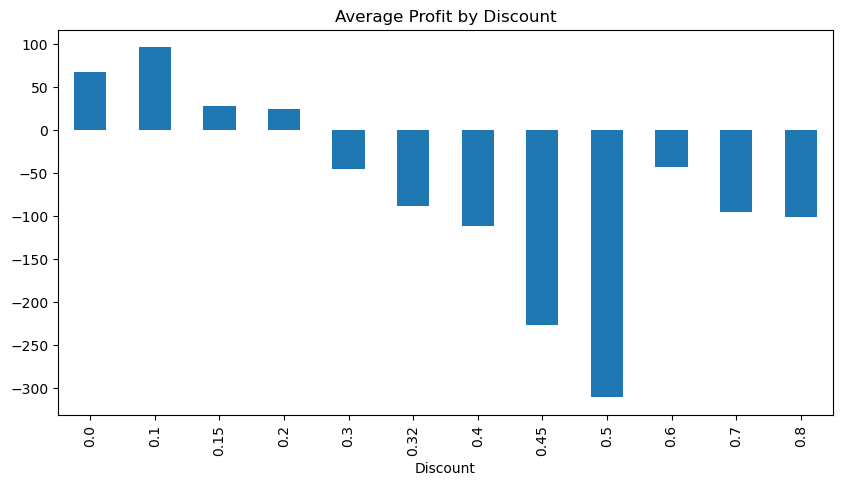

In [24]:
clean_df.groupby('Discount')['Profit'].mean().plot(
    kind='bar',
    figsize=(10,5),
    title='Average Profit by Discount'
)

In [25]:
(clean_df['Profit'] < 0).sum()

np.int64(1871)

In [26]:
(clean_df['Profit'] > 0).sum()

np.int64(8058)

In [27]:
(clean_df['Profit'] == 0).sum()

np.int64(65)

In [28]:
clean_df.isnull().sum()

Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Customer Name     0
Segment           0
Country           0
City              0
State             0
Postal Code      11
Region            0
Product ID        0
Category          0
Sub-Category      0
Product Name      0
Sales             0
Quantity          0
Discount          0
Profit            0
dtype: int64

In [46]:
clean_df.to_csv('cleaned_superstore.csv', index=False)

In [48]:
import os
import os
print(os.path.exists('cleaned_superstore.csv'))
print(os.path.getsize('cleaned_superstore.csv'))

True
2317021


In [32]:
customer_orders = clean_df.groupby('Customer Name')['Order ID'].nunique().sort_values(ascending=False)

customer_orders.head(10)

Customer Name
Emily Phan             17
Sally Hughsby          13
Erin Ashbrook          13
Patrick Gardner        13
Zuschuss Carroll       13
Chloris Kastensmidt    13
Joel Eaton             13
Noel Staavos           13
Rick Bensley           12
Resi Pölking           12
Name: Order ID, dtype: int64

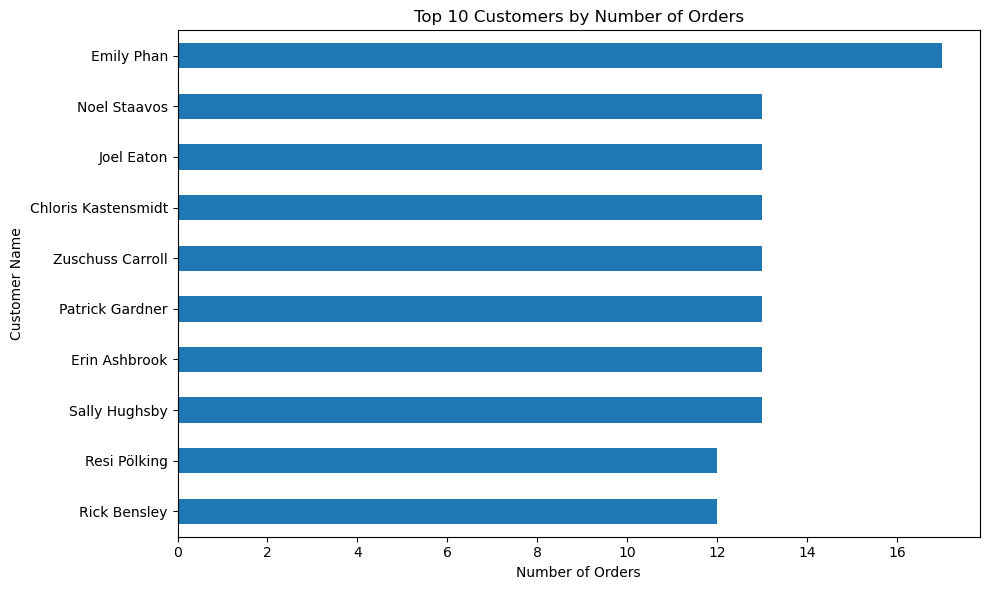

In [33]:
import matplotlib.pyplot as plt

customer_orders.head(10).sort_values().plot(kind='barh', figsize=(10, 6))

plt.title('Top 10 Customers by Number of Orders')
plt.xlabel('Number of Orders')
plt.ylabel('Customer Name')
plt.tight_layout()
plt.show()

In [34]:
monthly_sales = clean_df.groupby(clean_df['Order Date'].dt.to_period('M'))['Sales'].sum()

monthly_sales.head(10)

Order Date
2015-01    14236.8950
2015-02     4519.8920
2015-03    55691.0090
2015-04    28295.3450
2015-05    23648.2870
2015-06    34595.1276
2015-07    33946.3930
2015-08    27909.4685
2015-09    81777.3508
2015-10    31453.3930
Freq: M, Name: Sales, dtype: float64

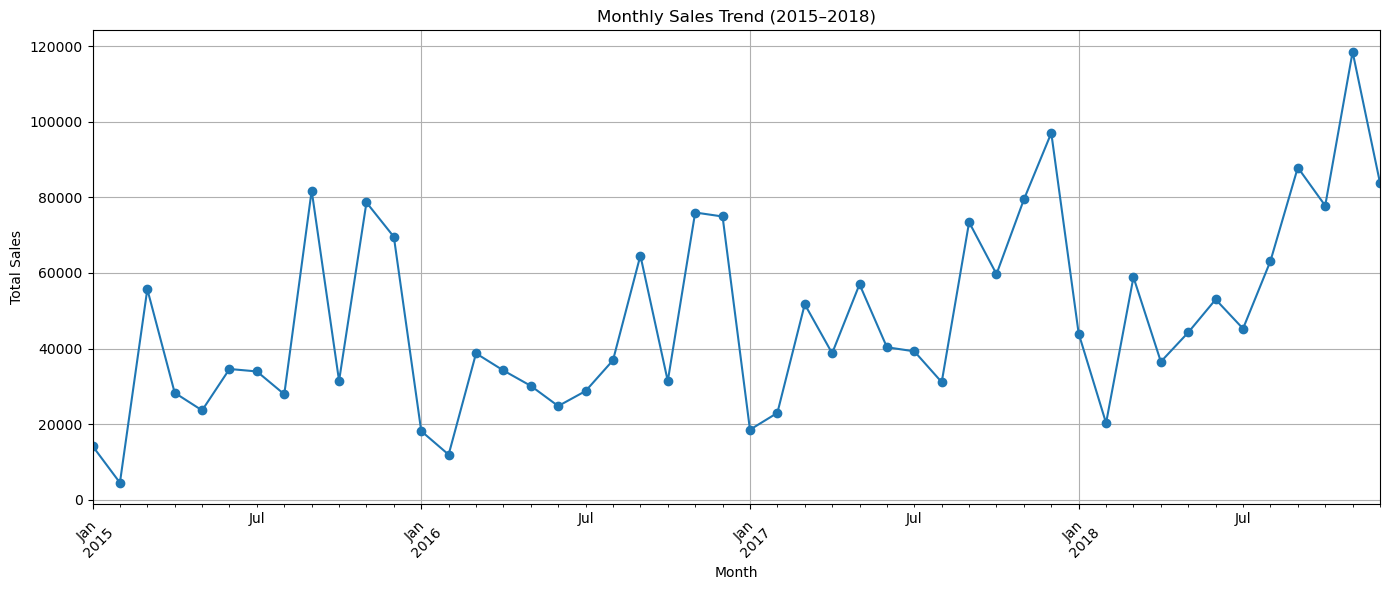

In [35]:
plt.figure(figsize=(14, 6))

monthly_sales.plot(kind='line', marker='o')

plt.title('Monthly Sales Trend (2015–2018)')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [36]:
category_sales = clean_df.groupby('Category')['Sales'].sum().sort_values(ascending=False)

category_sales

Category
Technology         836154.0330
Furniture          741999.7953
Office Supplies    719047.0320
Name: Sales, dtype: float64

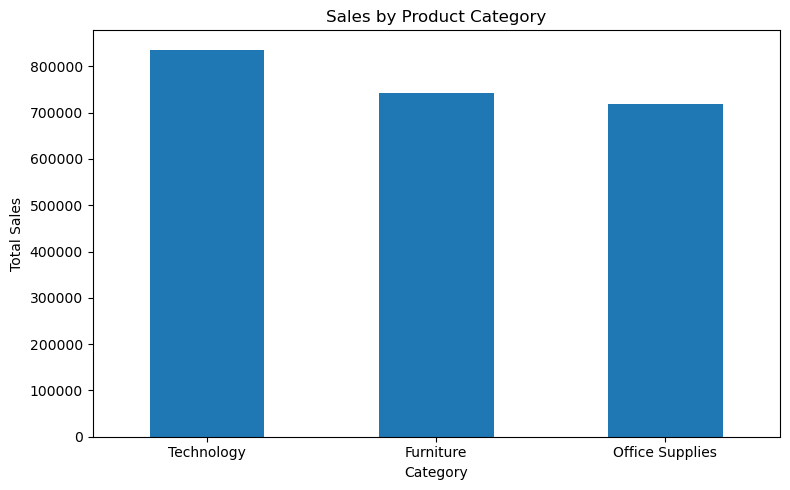

In [37]:
category_sales.plot(kind='bar', figsize=(8, 5))

plt.title('Sales by Product Category')
plt.xlabel('Category')
plt.ylabel('Total Sales')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [38]:
region_sales = clean_df.groupby('Region')['Sales'].sum().sort_values(ascending=False)

region_sales

Region
West       725457.8245
East       678781.2400
Central    501239.8908
South      391721.9050
Name: Sales, dtype: float64

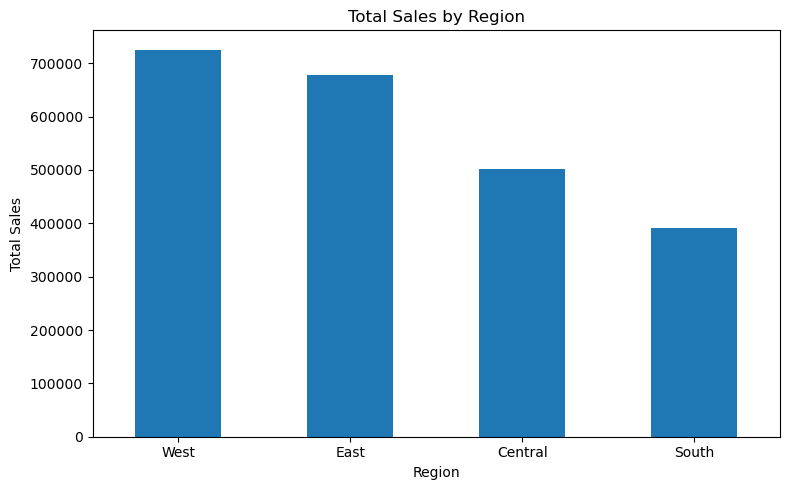

In [39]:
region_sales.plot(kind='bar', figsize=(8, 5))

plt.title('Total Sales by Region')
plt.xlabel('Region')
plt.ylabel('Total Sales')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [40]:
region_profit = clean_df.groupby('Region')['Profit'].sum().sort_values(ascending=False)

region_profit

Region
West       108418.4489
East        91522.7800
South       46749.4303
Central     39706.3625
Name: Profit, dtype: float64

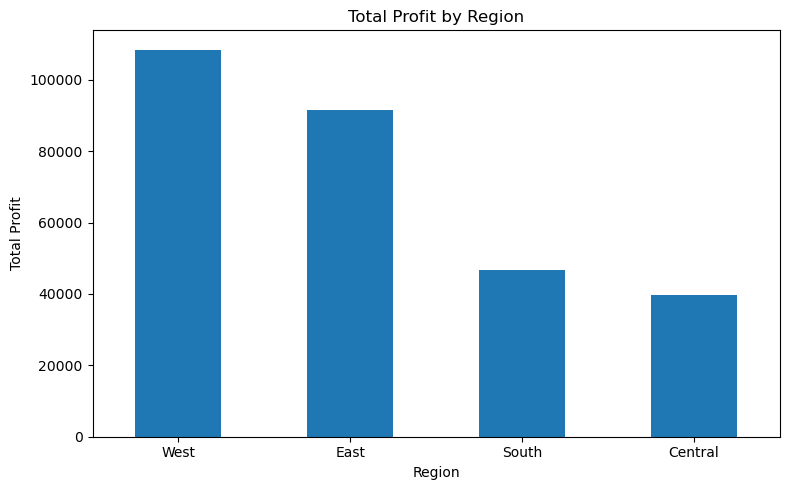

In [41]:
region_profit.plot(kind='bar', figsize=(8, 5))

plt.title('Total Profit by Region')
plt.xlabel('Region')
plt.ylabel('Total Profit')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

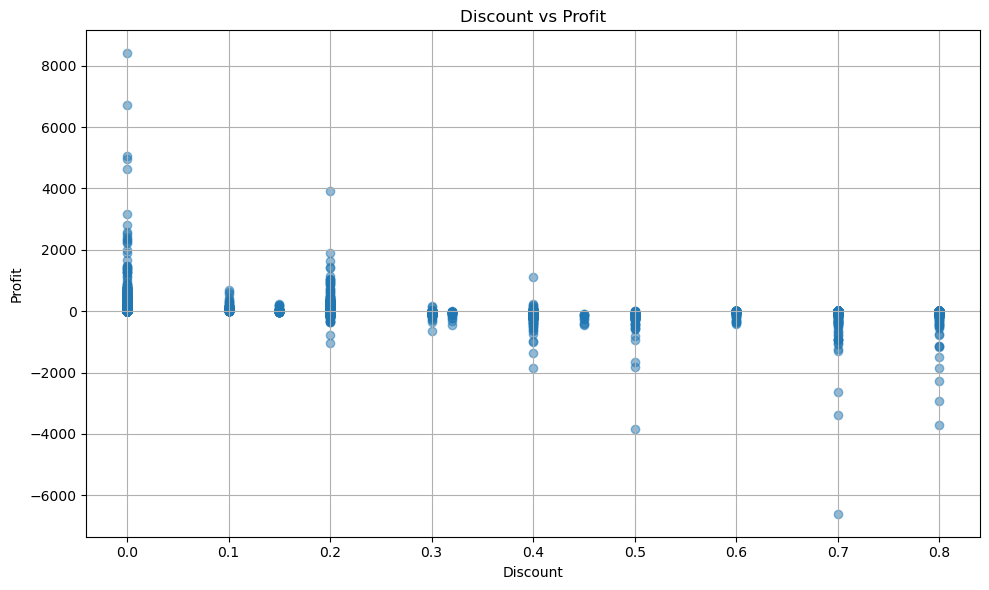

In [42]:
plt.figure(figsize=(10, 6))

plt.scatter(clean_df['Discount'], clean_df['Profit'], alpha=0.5)

plt.title('Discount vs Profit')
plt.xlabel('Discount')
plt.ylabel('Profit')
plt.grid(True)
plt.tight_layout()
plt.show()

In [43]:
discount_profit = clean_df.groupby('Discount')['Profit'].mean().round(2)

discount_profit

Discount
0.00     66.90
0.10     96.06
0.15     27.29
0.20     24.70
0.30    -45.68
0.32    -88.56
0.40   -111.93
0.45   -226.65
0.50   -310.70
0.60    -43.08
0.70    -95.87
0.80   -101.80
Name: Profit, dtype: float64

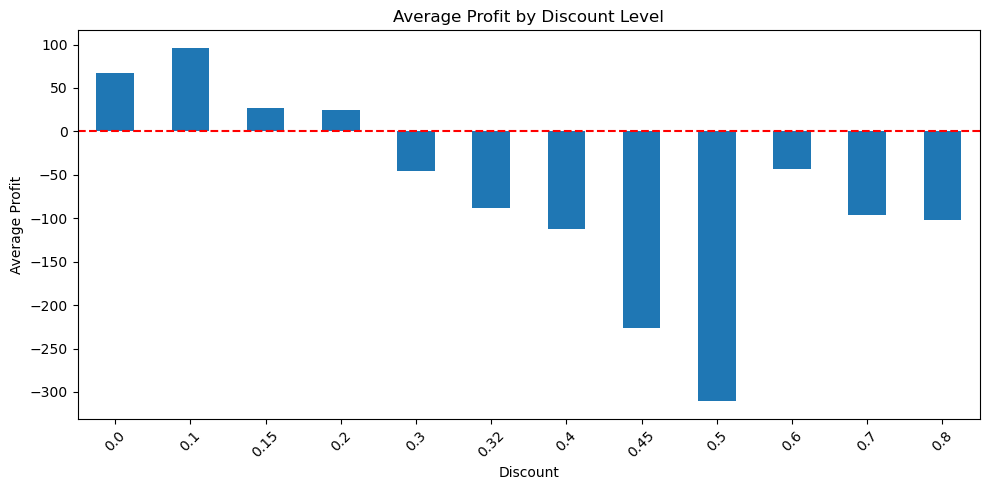

In [44]:
discount_profit.plot(kind='bar', figsize=(10, 5))

plt.title('Average Profit by Discount Level')
plt.xlabel('Discount')
plt.ylabel('Average Profit')
plt.axhline(y=0, color='red', linestyle='--')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [45]:
print("Total Sales:", round(clean_df['Sales'].sum(), 2))
print("Total Profit:", round(clean_df['Profit'].sum(), 2))
print("Total Quantity Sold:", clean_df['Quantity'].sum())
print("Total Orders:", clean_df['Order ID'].nunique())
print("Average Order Sales:", round(clean_df.groupby('Order ID')['Sales'].sum().mean(), 2))

Total Sales: 2297200.86
Total Profit: 286397.02
Total Quantity Sold: 37873
Total Orders: 5009
Average Order Sales: 458.61


# Exploratory Data Analysis – Superstore Retail Sales

## 1. Project Overview
The objective of this project was to explore Superstore retail sales data, identify sales trends, evaluate customer purchasing behaviour, and understand the factors affecting profitability.

## 2. Data Cleaning Summary
- Original dataset contained 10,800 rows and 21 columns.
- Removed 806 malformed rows that were not valid transaction records.
- Final cleaned dataset contains 9,994 records and 21 columns.
- Confirmed zero duplicate rows in the cleaned dataset.
- Retained 11 missing postal codes because their correct values could not be determined.
- Converted Order Date and Ship Date into datetime format.
- Converted Quantity into integer format.

## 3. Overall Business Performance
- Total Sales: 2,297,200.86
- Total Profit: 286,397.02
- Total Quantity Sold: 37,873
- Total Unique Orders: 5,009
- Average Sales per Order: 458.61

## 4. Key Findings
1. Emily Phan was the top customer by number of unique orders, with 17 orders.
2. Monthly sales fluctuated considerably, with noticeable peaks toward the end of the year.
3. Technology was the highest-revenue category, generating 836,154.03 in sales.
4. The West region generated the highest sales and profit.
5. The South region generated the lowest sales, while Central generated the lowest profit.
6. Higher discount levels were generally associated with lower average profits. Average profit was negative at discount levels of 30% and above.

## 5. Business Recommendations
- Introduce customer loyalty programs to encourage repeat purchases.
- Focus on high-performing technology products.
- Investigate opportunities to improve sales in the South region.
- Review discount policies, especially discounts of 30% or higher.
- Monitor regional profitability alongside revenue when making business decisions.

## 6. Conclusion
The exploratory analysis identified important patterns in customer purchasing behaviour, monthly sales, category performance, regional performance, and discount impact.

Technology and the West region were the strongest revenue contributors. The discount analysis highlighted potential profitability risks associated with higher discounts.

These findings can help the business improve sales strategies, customer retention, regional performance, and overall profitability.

